# TP Final — Inteligencia Artificial 2026 (UNAB)
## Etapa 1: Exploración (EDA), Partición de Datos y Modelo Baseline
### Predicción del siguiente carácter sobre *"The Festival"* (H. P. Lovecraft)

**Estudiantes:** Leonardo Carabajal, Brian Fernandez, Thiago Montenegro Yerumini  
**Docente:** Pablo Moreira  
**Dataset asignado:** *The Festival* de H. P. Lovecraft (texto literario, cuentos de terror)  

---

### Definición de la tarea supervisada
El objetivo del proyecto es construir un modelo generativo de texto a nivel de caracteres. En esta primera etapa formulamos el problema como una tarea de **clasificación multiclase supervisada**:
- **Entrada ($X$):** Una ventana de contexto de $L = 40$ caracteres consecutivos.
- **Objetivo ($y$):** El carácter inmediato siguiente a predecir (una clase dentro del vocabulario $|V|$).

### Decisiones metodológicas adoptadas
1. **Limpieza reproducible en el notebook:** Se parte del archivo original tal como fue provisto (`The_Festival.txt`), documentando el impacto de cada transformación.
2. **Partición por bloques contiguos (70% Train, 15% Dev, 15% Test):** Se divide el texto en bloques continuos para evitar la fuga de información (*data leakage*) que ocurriría al mezclar ventanas deslizantes adyacentes.
3. **Conservación del vocabulario completo:** Se mantienen todos los caracteres reales del texto para que el conjunto de desarrollo (Dev) refleje fielmente el desafío de las etapas posteriores.
4. **Métrica de evaluación principal:** *Accuracy* en el conjunto Dev, comparado directamente con la referencia trivial de la clase mayoritaria.
5. **Modelo baseline simple:** Regresión Logística multinomial sobre una codificación One-Hot de los últimos $K$ caracteres de contexto (equivalente a una red de una capa con activación Softmax).
6. **Persistencia de artefactos:** Las particiones, el vocabulario y la métrica de referencia se exportan a `data/processed/` para garantizar consistencia con las Etapas 2 y 3.

In [1]:
# ==============================================================================
# 0. CONFIGURACIÓN DEL ENTORNO E IMPORTACIÓN DE BIBLIOTECAS
# ==============================================================================
import os
import re
import json
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

# Estilo visual para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

# Semilla de aleatoriedad fija para reproducibilidad
SEED = 42
np.random.seed(SEED)

print("Entorno y bibliotecas configurados correctamente.")


Entorno y bibliotecas configurados correctamente.


---
# 1. Consigna 4.1.1: Carga y Análisis Exploratorio del Dataset (EDA)

## 1.1 Carga del archivo original y preprocesamiento de limpieza
Cargamos `The_Festival.txt` directamente desde su fuente original sin modificaciones externas. A continuación, aplicamos un conjunto mínimo de transformaciones reproducibles:

| Paso | Transformación | Justificación |
|---|---|---|
| 1. Fin de línea | `CRLF` $\to$ `LF` | Estandariza los saltos de línea y elimina el retorno de carro `\r` de Windows. |
| 2. Etiquetas HTML | Eliminación de `<i>` y `</i>` | Son etiquetas de maquetación tipográfica que no pertenecen al texto literario. |
| 3. Tipografía | Comillas y apóstrofos curvos $\to$ rectos | Normaliza variantes tipográficas idénticas sin perder información textual. |
| 4. Espaciado y saltos | Múltiples espacios/saltos $\to$ un espacio (`' '`) | El archivo original corta las líneas cada ~70 caracteres por formato visual. Al predecir con ventanas de 40 caracteres, esos saltos forzados agregarían ruido arbitrario. |

In [2]:
# ==============================================================================
# CARGA DEL ARCHIVO ORIGINAL (sin modificar)
# ==============================================================================
if (Path.cwd() / "db").exists():
    BASE_DIR = Path.cwd()
elif (Path.cwd().parent / "db").exists():
    BASE_DIR = Path.cwd().parent
elif (Path.cwd() / "ia-generacion-caracteres" / "ia-generacion-caracteres" / "db").exists():
    BASE_DIR = Path.cwd() / "ia-generacion-caracteres" / "ia-generacion-caracteres"
else:
    BASE_DIR = Path.cwd()

candidatos = [
    BASE_DIR / "db" / "The_Festival.txt",
    BASE_DIR / "The_Festival.txt",
    Path.cwd() / "ia-generacion-caracteres" / "ia-generacion-caracteres" / "db" / "The_Festival.txt"
]
RAW_PATH = next((p for p in candidatos if p.exists()), None)
if RAW_PATH is None:
    raise FileNotFoundError("No se encontró The_Festival.txt en las rutas esperadas.")

with open(RAW_PATH, "r", encoding="utf-8", newline="") as f:
    raw = f.read()

print(f"Archivo original: {RAW_PATH.name}")
print(f"Total de caracteres leídos: {len(raw):,}")
print(f"Saltos de línea CRLF: {raw.count(chr(13) + chr(10))}")
print(f"Etiquetas <i> o </i> presentes: {len(re.findall(r'</?i>', raw))}")
print("Símbolos no alfabéticos detectados:", sorted({c for c in raw if not c.isalpha()}))


Archivo original: The_Festival.txt
Total de caracteres leídos: 20,511
Saltos de línea CRLF: 321
Etiquetas <i> o </i> presentes: 2
Símbolos no alfabéticos detectados: ['\n', '\r', ' ', ',', '-', '.', '/', '0', '1', '2', '5', '6', '8', '9', ':', ';', '<', '>', '—', '’', '“', '”']


In [3]:
# ==============================================================================
# LIMPIEZA PASO A PASO DEL TEXTO
# ==============================================================================
pasos = [
    ("1. CRLF -> LF", lambda t: t.replace("\r\n", "\n").replace("\r", "\n")),
    ("2. Quitar <i> y </i>", lambda t: re.sub(r"</?i>", "", t)),
    ("3. Comillas curvas a rectas", lambda t: t.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')),
    ("4. Estandarizar espacios y saltos", lambda t: re.sub(r"\s+", " ", t).strip()),
]

text = raw
registro = [("Original", len(text), len(set(text)))]
for nombre, fn in pasos:
    text = fn(text)
    registro.append((nombre, len(text), len(set(text))))

df_limpieza = pd.DataFrame(registro, columns=["Paso", "Caracteres totales", "Vocabulario (|V|)"])
print(df_limpieza.to_string(index=False))
print(f"\nFragmento inicial: {text[:65]!r}")
print(f"Fragmento final:   {text[-65:]!r}")


                             Paso  Caracteres totales  Vocabulario (|V|)
                         Original               20511                 70
                    1. CRLF -> LF               20190                 69
             2. Quitar <i> y </i>               20183                 66
      3. Comillas curvas a rectas               20183                 65
4. Estandarizar espacios y saltos               20180                 64

Fragmento inicial: 'I was far from home, and the spell of the eastern sea was upon me'
Fragmento final:   ' to suffice, and things have learnt to walk that ought to crawl."'


## 1.2 Descripción de las variables
Al trabajar con un corpus de texto continuo para modelado de lenguaje a nivel de caracteres, las variables se definen a partir de la formulación supervisada:

| Variable | Rol | Tipo de dato | Dominio / Rango |
|---|---|---|---|
| `X` | Contexto de entrada | Secuencia de caracteres | Cadena de longitud fija $L = 40$ |
| `y` | Carácter objetivo (clase) | Categórica nominal | Un carácter del vocabulario $|V|$ |

- **Valores nulos:** $0$. No existen valores faltantes en el texto; cada posición contiene un carácter válido.

In [4]:
# ==============================================================================
# ESTADÍSTICAS BÁSICAS DEL CORPUS
# ==============================================================================
vocabulary = sorted(set(text))
vocab_size = len(vocabulary)
char_counts = Counter(text)

words = re.findall(r"[A-Za-z]+(?:['-][A-Za-z]+)*", text)
word_lengths = np.array([len(w) for w in words])
sentences = [s for s in re.split(r"[.!?]+", text) if s.strip()]

resumen = pd.Series({
    "Caracteres totales": f"{len(text):,}",
    "Vocabulario de caracteres (|V|)": vocab_size,
    "Palabras totales": f"{len(words):,}",
    "Palabras distintas (vocabulario léxico)": len({w.lower() for w in words}),
    "Oraciones estimadas": len(sentences),
    "Valores nulos": 0
}, name="Valor")

print(resumen.to_string())
print(f"\nVocabulario completo ({vocab_size} caracteres):\n{''.join(vocabulary)!r}")


Caracteres totales                         20,180
Vocabulario de caracteres (|V|)                64
Palabras totales                            3,578
Palabras distintas (vocabulario léxico)      1240
Oraciones estimadas                           119
Valores nulos                                   0

Vocabulario completo (64 caracteres):
' "\',-.0125689:;ABCDEFGHIJKLMNOPRSTUWYabcdefghijklmnopqrstuvwxyz—'


### Gráfico 1: Distribución de frecuencia de caracteres (desbalance de clases)
Dado que cada carácter del vocabulario representa una clase a predecir, graficamos los 20 caracteres más frecuentes frente a los 20 menos frecuentes para evidenciar el desbalance inherente al lenguaje natural.

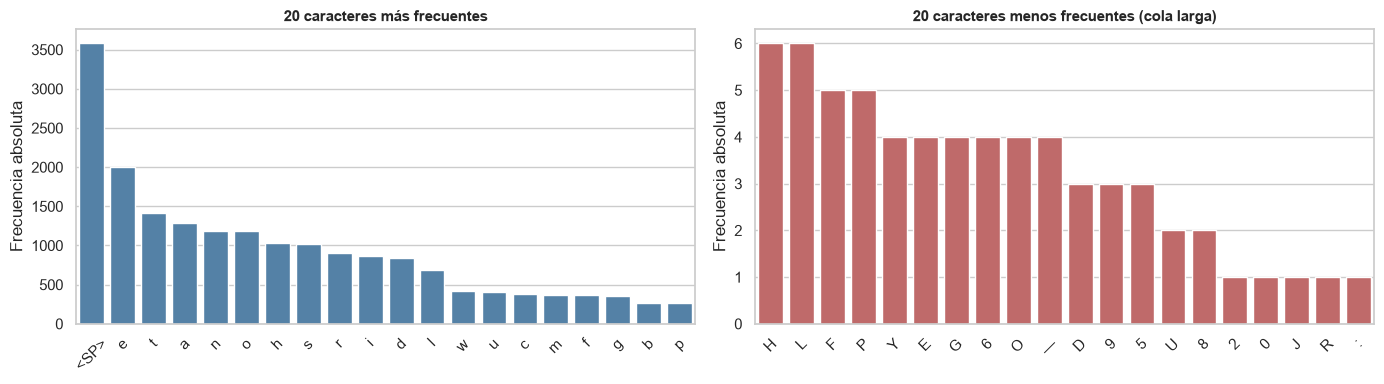

In [5]:
def vis(c):
    return {" ": "<SP>", "\n": "<NL>"}.get(str(c), str(c))

serie = pd.Series(char_counts).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

top20 = serie.head(20)
sns.barplot(x=[vis(c) for c in top20.index], y=top20.values, ax=axes[0], color="steelblue")
axes[0].set_title("20 caracteres más frecuentes", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Frecuencia absoluta")
axes[0].tick_params(axis="x", rotation=45)

bottom20 = serie.tail(20)
sns.barplot(x=[vis(c) for c in bottom20.index], y=bottom20.values, ax=axes[1], color="indianred")
axes[1].set_title("20 caracteres menos frecuentes (cola larga)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Frecuencia absoluta")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


### Gráfico 2: Distribución de longitud de palabras
Permite caracterizar el estilo del autor (prosa de Lovecraft, rica en adjetivos y palabras arcaicas extensas).

Palabras más largas del cuento: ['great-great-great-great-grandfather', 'winter-whitened', 'preternaturally', 'phosphorescence', 'burying-ground', 'night-marchers']


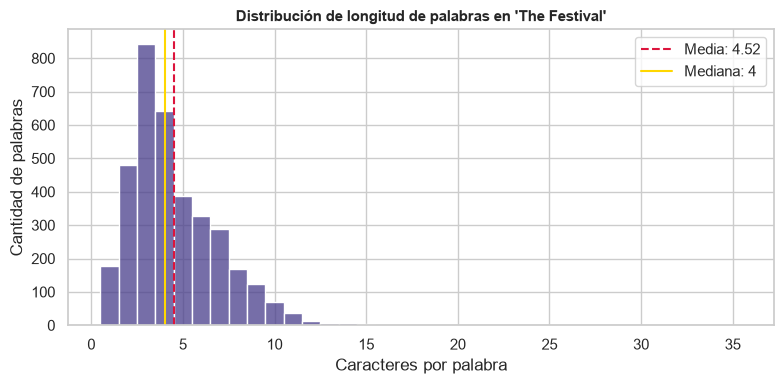

In [6]:
plt.figure(figsize=(8, 4))
sns.histplot(word_lengths, bins=range(1, word_lengths.max() + 2), discrete=True, color="darkslateblue")
plt.axvline(word_lengths.mean(), color="crimson", linestyle="--", label=f"Media: {word_lengths.mean():.2f}")
plt.axvline(np.median(word_lengths), color="gold", linestyle="-", label=f"Mediana: {np.median(word_lengths):.0f}")
plt.title("Distribución de longitud de palabras en 'The Festival'", fontsize=11, fontweight="bold")
plt.xlabel("Caracteres por palabra")
plt.ylabel("Cantidad de palabras")
plt.legend()
plt.tight_layout()
plt.show()

largas = sorted({w for w in words if len(w) >= 14}, key=len, reverse=True)
print("Palabras más largas del cuento:", largas[:6])


### Gráfico 3: Frecuencia de signos de puntuación
Describe la estructura oracional y los símbolos que el modelo deberá aprender a predecir adecuadamente.

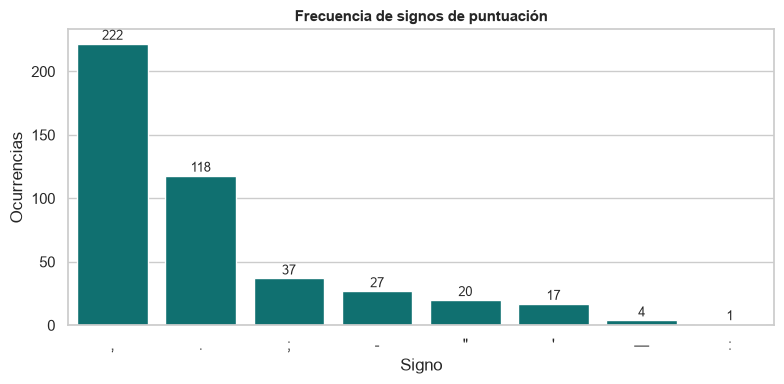

In [7]:
signos = set(".,;:!?'\"—-")
punct_counts = pd.Series([c for c in text if c in signos]).value_counts()

plt.figure(figsize=(8, 4))
sns.barplot(x=list(punct_counts.index), y=list(punct_counts.values), color="teal")
for i, n in enumerate(punct_counts.values):
    plt.text(i, n + 3, str(n), ha="center", fontsize=9)
plt.title("Frecuencia de signos de puntuación", fontsize=11, fontweight="bold")
plt.xlabel("Signo")
plt.ylabel("Ocurrencias")
plt.tight_layout()
plt.show()


### Diagnóstico de problemas potenciales: desbalance, outliers y estabilidad (data mismatch)
En cumplimiento del requisito 4.1.1, analizamos:
1. **Desbalance de clases:** El espacio en blanco `' '` y vocales como la `'e'` dominan el texto, mientras caracteres especiales aparecen de forma aislada.
2. **Outliers / Clases raras:** Caracteres que aparecen menos de 10 veces en todo el texto literario.
3. **Estabilidad temporal (posible data mismatch):** Comparamos la distribución de caracteres de la primera mitad del relato contra la segunda para verificar que el estilo sea uniforme.

DIAGNÓSTICO DEL DATASET:
  • Desbalance: La clase mayoritaria '<SP>' representa el 17.7% del texto, mientras que ':' aparece solo 1 vez.
  • Outliers / Clases raras: 28 de 64 caracteres tienen menos de 10 apariciones: ['0', '1', '2', '5', '6', '8', '9', ':', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'U', 'W', 'Y', 'j', '—']
  • Estabilidad: Como muestra el gráfico comparativo, las frecuencias son sumamente estables entre mitades, descartando un data mismatch estilístico severo.


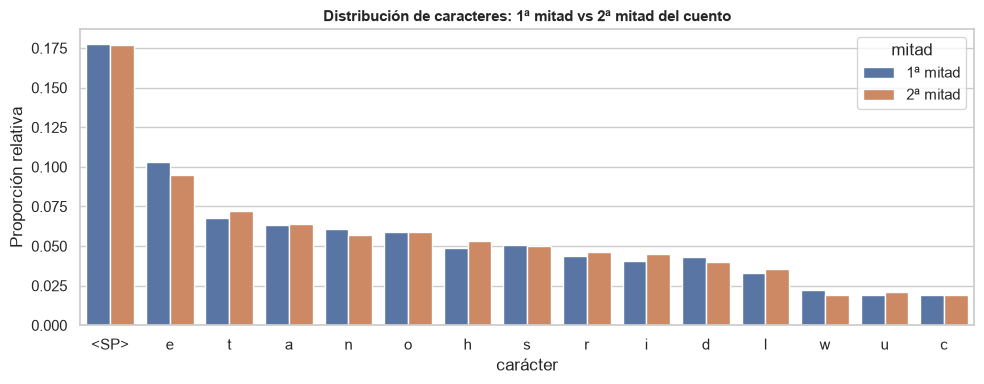

In [8]:
# Comparación de la 1ª mitad vs 2ª mitad del texto
mitad = len(text) // 2
c1, c2 = Counter(text[:mitad]), Counter(text[mitad:])
top15 = serie.index[:15]

df_mitades = pd.DataFrame({
    "carácter": [vis(c) for c in top15] * 2,
    "proporción": [c1[c] / mitad for c in top15] + [c2[c] / (len(text) - mitad) for c in top15],
    "mitad": ["1ª mitad"] * 15 + ["2ª mitad"] * 15
})

plt.figure(figsize=(10, 4))
sns.barplot(data=df_mitades, x="carácter", y="proporción", hue="mitad")
plt.title("Distribución de caracteres: 1ª mitad vs 2ª mitad del cuento", fontsize=11, fontweight="bold")
plt.ylabel("Proporción relativa")
plt.tight_layout()
plt.show()

raros = [c for c, n in char_counts.items() if n < 10]
print("DIAGNÓSTICO DEL DATASET:")
print(f"  • Desbalance: La clase mayoritaria '{vis(serie.index[0])}' representa el {serie.iloc[0]/len(text)*100:.1f}% del texto, mientras que '{vis(serie.index[-1])}' aparece solo {serie.iloc[-1]} vez.")
print(f"  • Outliers / Clases raras: {len(raros)} de {vocab_size} caracteres tienen menos de 10 apariciones: {sorted(vis(c) for c in raros)}")
print("  • Estabilidad: Como muestra el gráfico comparativo, las frecuencias son sumamente estables entre mitades, descartando un data mismatch estilístico severo.")


---
# 2. Consigna 4.1.2: Partición de datos (Train / Dev / Test)

## 2.1 Justificación de la estrategia de partición elegida
Si tomáramos ventanas deslizantes contiguas (paso de 1 carácter) y las dividiéramos con un `train_test_split` aleatorio estándar, ventanas vecinas quedarían repartidas entre entrenamiento y validación. Dado que dos ventanas adyacentes comparten 39 de sus 40 caracteres, el modelo evaluaría ejemplos prácticamente idénticos a los de entrenamiento (**fuga masiva de datos**).

**Estrategia adoptada: Partición por bloques contiguos (70% Train / 15% Dev / 15% Test)**
1. Se divide el texto en bloques contiguos de ~400 caracteres.
2. Cada bloque completo se asigna al azar a Train, Dev o Test con semilla fija.
3. Las ventanas de cada conjunto se generan **estrictamente dentro** de sus propios bloques.

Esta metodología previene cualquier solapamiento entre particiones y garantiza que Train, Dev y Test contengan muestras representativas a lo largo de todo el relato.

In [9]:
# ==============================================================================
# PARTICIÓN POR BLOQUES CONTIGUOS (70% Train / 15% Dev / 15% Test)
# ==============================================================================
L = 40        # Longitud de la ventana de contexto
BLOQUE = 400  # Caracteres por bloque contiguo

limites = [(i, min(i + BLOQUE, len(text))) for i in range(0, len(text), BLOQUE)]
if limites[-1][1] - limites[-1][0] < BLOQUE // 2:
    ini_prev = limites[-2][0]
    limites = limites[:-2] + [(ini_prev, len(text))]

n_bloques = len(limites)
rng = np.random.default_rng(SEED)
orden = rng.permutation(n_bloques)

n_tr = round(0.70 * n_bloques)
n_dev = round(0.15 * n_bloques)

bloques_split = {
    "train": sorted(orden[:n_tr].tolist()),
    "dev":   sorted(orden[n_tr:n_tr + n_dev].tolist()),
    "test":  sorted(orden[n_tr + n_dev:].tolist()),
}

def ventanas_de_bloques(ids):
    X, y = [], []
    for b in ids:
        ini, fin = limites[b]
        for i in range(ini, fin - L):
            X.append(text[i:i+L])
            y.append(text[i+L])
    return X, y

X_train, y_train = ventanas_de_bloques(bloques_split["train"])
X_dev,   y_dev   = ventanas_de_bloques(bloques_split["dev"])
X_test,  y_test  = ventanas_de_bloques(bloques_split["test"])

n_total = len(X_train) + len(X_dev) + len(X_test)
print(f"Bloques totales: {n_bloques} (~{BLOQUE} caracteres c/u) -> Train: {len(bloques_split['train'])} | Dev: {len(bloques_split['dev'])} | Test: {len(bloques_split['test'])}")
print(f"  • Train: {len(X_train):>6,} muestras ({len(X_train)/n_total*100:4.1f}%)")
print(f"  • Dev:   {len(X_dev):>6,} muestras ({len(X_dev)/n_total*100:4.1f}%)")
print(f"  • Test:  {len(X_test):>6,} muestras ({len(X_test)/n_total*100:4.1f}%)")
print(f"\nEjemplo extraído:\n  Contexto X: {X_train[0]!r}\n  Objetivo y: {y_train[0]!r}")


Bloques totales: 50 (~400 caracteres c/u) -> Train: 35 | Dev: 8 | Test: 7
  • Train: 12,780 muestras (70.3%)
  • Dev:    2,880 muestras (15.8%)
  • Test:   2,520 muestras (13.9%)

Ejemplo extraído:
  Contexto X: 'e tongue of the blue-eyed fishers. And n'
  Objetivo y: 'o'


## 2.2 Verificación de la distribución de clases en los tres conjuntos
Comprobamos que las proporciones de los caracteres objetivo sean consistentes en Train, Dev y Test.

Caracteres en Dev/Test pero ausentes en Train: ['2']


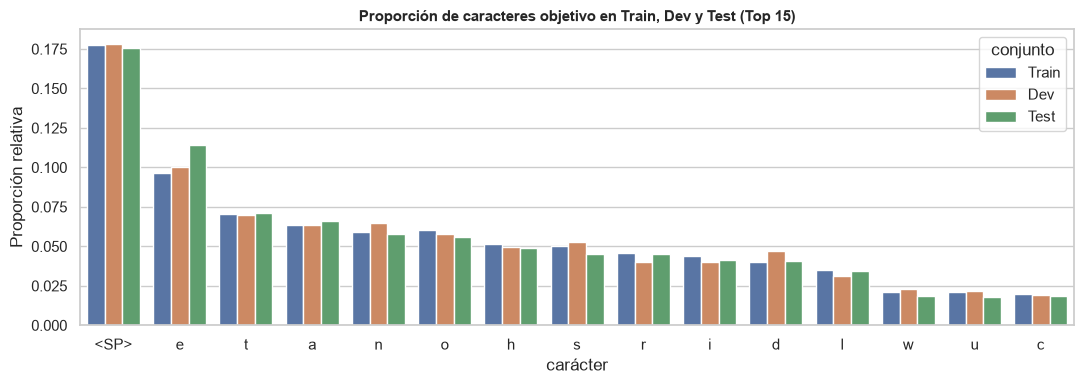

In [10]:
conteos = {
    "Train": Counter(y_train),
    "Dev":   Counter(y_dev),
    "Test":  Counter(y_test),
}

freq = pd.DataFrame({s: pd.Series(c).reindex(vocabulary, fill_value=0) for s, c in conteos.items()})
prop = freq / freq.sum()

top15 = serie.index[:15]
df_p = prop.loc[top15].reset_index(names="carácter").melt(id_vars="carácter", var_name="conjunto", value_name="proporción")
df_p["carácter"] = df_p["carácter"].map(vis)

plt.figure(figsize=(11, 4))
sns.barplot(data=df_p, x="carácter", y="proporción", hue="conjunto")
plt.title("Proporción de caracteres objetivo en Train, Dev y Test (Top 15)", fontsize=11, fontweight="bold")
plt.ylabel("Proporción relativa")
plt.tight_layout()
plt.show()

sin_train = [vis(c) for c in vocabulary if freq.loc[c, "Train"] == 0 and (freq.loc[c, "Dev"] + freq.loc[c, "Test"]) > 0]
print(f"Caracteres en Dev/Test pero ausentes en Train: {sin_train}")


---
# 3. Consigna 4.1.3: Preprocesamiento y modelo baseline

## 3.1 Codificación numérica y persistencia de particiones
Definimos el mapeo bidireccional entre caracteres y números enteros (`char2idx` e `idx2char`). Guardamos el texto procesado y las particiones en disco (`data/processed/`) para asegurar que las redes neuronales de las Etapas 2 y 3 utilicen exactamente los mismos datos de validación.

In [11]:
# ==============================================================================
# CODIFICACIÓN NUMÉRICA Y PERSISTENCIA
# ==============================================================================
char2idx = {c: i for i, c in enumerate(vocabulary)}
idx2char = {i: c for c, i in char2idx.items()}
V = len(vocabulary)

OUT_DIR = BASE_DIR / "data" / "processed"
OUT_DIR.mkdir(parents=True, exist_ok=True)

(OUT_DIR / "The_Festival_clean.txt").write_text(text, encoding="utf-8")
with open(OUT_DIR / "splits_bloques.json", "w", encoding="utf-8") as f:
    json.dump({
        "L": L,
        "BLOQUE": BLOQUE,
        "SEED": SEED,
        "limites_bloques": limites,
        "bloques": bloques_split,
        "vocabulario": "".join(vocabulary)
    }, f, ensure_ascii=False)

print(f"Vocabulario (|V| = {V}) y particiones guardados exitosamente en {OUT_DIR.relative_to(BASE_DIR)}/")


Vocabulario (|V| = 64) y particiones guardados exitosamente en data\processed/


## 3.2 Definición y justificación de la métrica de evaluación de número único
**Métrica elegida: Accuracy top-1 en Dev** (proporción de predicciones correctas sobre el total de ventanas evaluadas).

- **Justificación:** Es la métrica estándar, intuitiva y directamente interpretable en clasificación multiclase. Permite una comparación directa e inmediata contra la **referencia trivial (dummy baseline)** de predecir siempre el carácter más frecuente del idioma (el espacio en blanco).
- Las redes de las siguientes etapas (MLP y LSTM) buscarán superar este umbral de exactitud.

In [12]:
# ==============================================================================
# REFERENCIA TRIVIAL: PREDICCIÓN DE LA CLASE MAYORITARIA
# ==============================================================================
clase_mayoritaria = serie.index[0]
acc_dummy_dev = np.mean([y == clase_mayoritaria for y in y_dev])

print(f"Clase mayoritaria en el texto: '{vis(clase_mayoritaria)}'")
print(f"Accuracy de referencia trivial en Dev: {acc_dummy_dev:.4f} ({acc_dummy_dev*100:.2f}%)")


Clase mayoritaria en el texto: '<SP>'
Accuracy de referencia trivial en Dev: 0.1785 (17.85%)


## 3.3 Modelo baseline: Regresión Logística multinomial sobre los últimos $K$ caracteres
En la predicción de texto a nivel carácter, los caracteres inmediatamente precedentes al objetivo contienen la mayor cantidad de información predictiva inmediata (concepto de n-gramas).

Construimos un pipeline simple en scikit-learn:
1. Extraer los últimos $K$ caracteres de la ventana de contexto.
2. Aplicar codificación `OneHotEncoder` sobre esa secuencia de $K$ posiciones.
3. Entrenar una `LogisticRegression` multinomial (equivalente a una red de 1 capa densa con función Softmax).

Comparamos valores de contexto $K \in [1, 3, 5]$ evaluando en el conjunto Dev para fijar el mejor baseline.

   Accuracy Train  Accuracy Dev
K                              
1          0.3005        0.3122
3          0.4026        0.4069
5          0.4297        0.4083

Mejor K seleccionado con Dev: K = 5


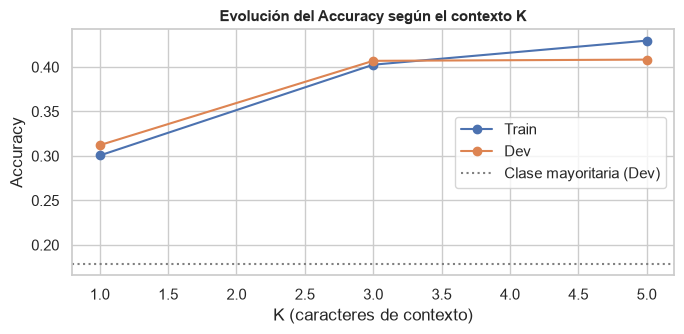

In [13]:
# ==============================================================================
# ENTRENAMIENTO DEL BASELINE CON VARIACIÓN DE CONTEXTO K
# ==============================================================================
def ultimos(X, k):
    return np.array([list(x[-k:]) for x in X])

resultados_k = []
modelos_k = {}

for k in [1, 3, 5]:
    pipe = Pipeline([
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ("clf", LogisticRegression(max_iter=500, random_state=SEED)),
    ])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        pipe.fit(ultimos(X_train, k), y_train)
    
    modelos_k[k] = pipe
    acc_tr = accuracy_score(y_train, pipe.predict(ultimos(X_train, k)))
    acc_dev = accuracy_score(y_dev, pipe.predict(ultimos(X_dev, k)))
    resultados_k.append({"K": k, "Accuracy Train": acc_tr, "Accuracy Dev": acc_dev})

df_k = pd.DataFrame(resultados_k).set_index("K")
print(df_k.round(4))

K_OPTIMO = int(df_k["Accuracy Dev"].idxmax())
print(f"\nMejor K seleccionado con Dev: K = {K_OPTIMO}")

plt.figure(figsize=(7, 3.5))
plt.plot(df_k.index, df_k["Accuracy Train"], marker="o", label="Train")
plt.plot(df_k.index, df_k["Accuracy Dev"], marker="o", label="Dev")
plt.axhline(acc_dummy_dev, color="gray", linestyle=":", label="Clase mayoritaria (Dev)")
plt.xlabel("K (caracteres de contexto)")
plt.ylabel("Accuracy")
plt.title("Evolución del Accuracy según el contexto K", fontsize=11, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.show()


## 3.4 Reporte oficial del resultado del Baseline en Dev
De acuerdo con la consigna 4.1.3, reportamos el desempeño del modelo baseline en el conjunto Dev. Este número constituirá la **línea de base oficial** que las arquitecturas neuronales de las etapas subsiguientes deberán superar.

In [14]:
# ==============================================================================
# REPORTE OFICIAL DEL BASELINE EN DEV (Consigna 4.1.3)
# ==============================================================================
baseline_final = modelos_k[K_OPTIMO]
Xdev_opt = ultimos(X_dev, K_OPTIMO)
y_pred_dev = baseline_final.predict(Xdev_opt)

acc_base_dev = accuracy_score(y_dev, y_pred_dev)

print("=" * 70)
print(f"BASELINE OFICIAL — One-Hot últimos {K_OPTIMO} caracteres + Regresión Logística:")
print(f"  • Accuracy en Dev: {acc_base_dev:.4f} ({acc_base_dev*100:.2f}%)")
print(f"  • Referencia trivial (clase mayoritaria): {acc_dummy_dev:.4f} ({acc_dummy_dev*100:.2f}%)")
print(f"  • Ganancia sobre la referencia trivial: +{(acc_base_dev - acc_dummy_dev)*100:.2f} puntos porcentuales")
print(f"  • Muestras evaluadas en Dev: {len(y_dev)}")
print("=" * 70)

# Guardar en disco para referencia futura en Etapa 2 y 5
with open(OUT_DIR / "baseline_dev.json", "w", encoding="utf-8") as f:
    json.dump({
        "modelo": f"OneHot_ultimos_{K_OPTIMO}_chars + LogisticRegression",
        "K": K_OPTIMO,
        "metrica_principal": "accuracy_dev",
        "accuracy_dev": float(acc_base_dev),
        "accuracy_dummy_dev": float(acc_dummy_dev),
        "n_dev": len(y_dev)
    }, f, indent=2)
print("Métrica oficial guardada en data/processed/baseline_dev.json")


BASELINE OFICIAL — One-Hot últimos 5 caracteres + Regresión Logística:
  • Accuracy en Dev: 0.4083 (40.83%)
  • Referencia trivial (clase mayoritaria): 0.1785 (17.85%)
  • Ganancia sobre la referencia trivial: +22.99 puntos porcentuales
  • Muestras evaluadas en Dev: 2880
Métrica oficial guardada en data/processed/baseline_dev.json


## 3.5 Diagnóstico de errores del baseline (Matriz de confusión)
Analizamos la matriz de confusión normalizada sobre las 20 clases principales para entender los errores del modelo lineal.

Total de errores en Dev: 1704 de 2880

Pares de caracteres más confundidos (real -> predicho):
Real Predicho  Ocurrencias
   e     <SP>           65
   s     <SP>           42
   a        e           37
   t     <SP>           33
   s        t           33
   n     <SP>           28
   e        o           28
   o        e           27


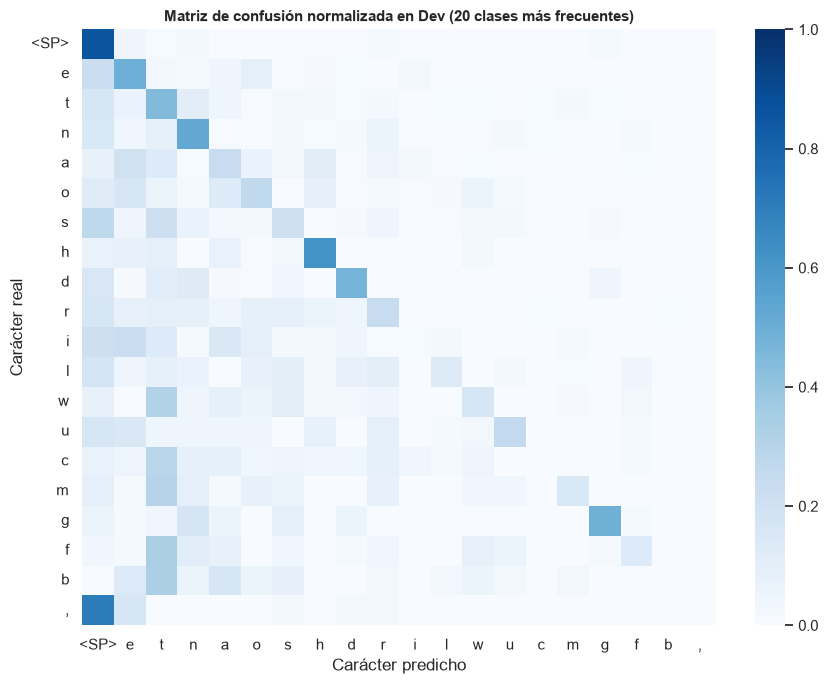

In [15]:
# ==============================================================================
# MATRIZ DE CONFUSIÓN Y ANÁLISIS DE ERRORES EN DEV
# ==============================================================================
labels_all = sorted(set(y_dev) | set(y_pred_dev))
cm = confusion_matrix(y_dev, y_pred_dev, labels=labels_all, normalize="true")

top20 = [c for c, _ in Counter(y_dev).most_common(20)]
ix = [labels_all.index(c) for c in top20]

plt.figure(figsize=(9, 7))
sns.heatmap(cm[np.ix_(ix, ix)], cmap="Blues", vmin=0, vmax=1,
            xticklabels=[vis(c) for c in top20], yticklabels=[vis(c) for c in top20])
plt.title("Matriz de confusión normalizada en Dev (20 clases más frecuentes)", fontsize=11, fontweight="bold")
plt.xlabel("Carácter predicho")
plt.ylabel("Carácter real")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

errores = [(r, p) for r, p in zip(y_dev, y_pred_dev) if r != p]
top_errores = Counter(errores).most_common(8)
print(f"Total de errores en Dev: {len(errores)} de {len(y_dev)}")
print("\nPares de caracteres más confundidos (real -> predicho):")
df_err = pd.DataFrame([(vis(r), vis(p), n) for (r, p), n in top_errores], columns=["Real", "Predicho", "Ocurrencias"])
print(df_err.to_string(index=False))


---
# 4. Síntesis y Checklist de la Etapa 1
Resumen del estado de entrega según los requerimientos obligatorios de la cátedra.

In [16]:
print("CHECKLIST DE CUMPLIMIENTO - ETAPA 1")
print(f"  [x] 4.1.1 Carga y EDA: {len(text):,} caracteres, |V| = {vocab_size}, 3 gráficos descriptivos y diagnóstico de problemas.")
print(f"  [x] 4.1.2 Partición: Train ({len(X_train):,}) / Dev ({len(X_dev):,}) / Test ({len(X_test):,}) mediante bloques contiguos sin data leakage.")
print("  [x] 4.1.2 Proporción de clases verificada en los tres conjuntos.")
print(f"  [x] 4.1.3 Preprocesamiento y Baseline: One-Hot de últimos {K_OPTIMO} caracteres + Regresión Logística multinomial.")
print(f"  [x] 4.1.3 Métrica de número único: Accuracy en Dev = {acc_base_dev:.4f} (referencia trivial = {acc_dummy_dev:.4f}).")
print("  [x] Particiones, vocabulario y baseline guardados en data/processed/ para la Etapa 2.")
print("  [x] Conjunto Test preservado estrictamente intacto para la evaluación final en la Etapa 5.")


CHECKLIST DE CUMPLIMIENTO - ETAPA 1
  [x] 4.1.1 Carga y EDA: 20,180 caracteres, |V| = 64, 3 gráficos descriptivos y diagnóstico de problemas.
  [x] 4.1.2 Partición: Train (12,780) / Dev (2,880) / Test (2,520) mediante bloques contiguos sin data leakage.
  [x] 4.1.2 Proporción de clases verificada en los tres conjuntos.
  [x] 4.1.3 Preprocesamiento y Baseline: One-Hot de últimos 5 caracteres + Regresión Logística multinomial.
  [x] 4.1.3 Métrica de número único: Accuracy en Dev = 0.4083 (referencia trivial = 0.1785).
  [x] Particiones, vocabulario y baseline guardados en data/processed/ para la Etapa 2.
  [x] Conjunto Test preservado estrictamente intacto para la evaluación final en la Etapa 5.
